In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Dataset/World_Happiness_Report_full.csv")
df


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.164055,0.881686,0.414297,0.258195
1,Afghanistan,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.187297,0.850035,0.481421,0.237092
2,Afghanistan,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.117861,0.706766,0.516907,0.275324
3,Afghanistan,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.160098,0.731109,0.479835,0.267175
4,Afghanistan,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.234157,0.775620,0.613513,0.267919
...,...,...,...,...,...,...,...,...,...,...,...
2358,Zimbabwe,2019,2.693523,7.697755,0.759162,53.099998,0.631908,-0.050874,0.830652,0.658434,0.235354
2359,Zimbabwe,2020,3.159802,7.596050,0.717243,53.575001,0.643303,0.002848,0.788523,0.660658,0.345736
2360,Zimbabwe,2021,3.154578,7.656878,0.685151,54.049999,0.667636,-0.079007,0.756945,0.609917,0.241682
2361,Zimbabwe,2022,3.296220,7.670073,0.666172,54.525002,0.651987,-0.072935,0.752632,0.640609,0.191350


In [3]:
df.head()

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.164055,0.881686,0.414297,0.258195
1,Afghanistan,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.187297,0.850035,0.481421,0.237092
2,Afghanistan,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.117861,0.706766,0.516907,0.275324
3,Afghanistan,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.160098,0.731109,0.479835,0.267175
4,Afghanistan,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.234157,0.775620,0.613513,0.267919


In [4]:
df.tail()

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
2358,Zimbabwe,2019,2.693523,7.697755,0.759162,53.099998,0.631908,-0.050874,0.830652,0.658434,0.235354
2359,Zimbabwe,2020,3.159802,7.596050,0.717243,53.575001,0.643303,0.002848,0.788523,0.660658,0.345736
2360,Zimbabwe,2021,3.154578,7.656878,0.685151,54.049999,0.667636,-0.079007,0.756945,0.609917,0.241682
2361,Zimbabwe,2022,3.296220,7.670073,0.666172,54.525002,0.651987,-0.072935,0.752632,0.640609,0.191350
2362,Zimbabwe,2023,3.572386,7.678590,0.693817,55.000000,0.734613,-0.068837,0.757494,0.609752,0.178953


In [5]:
df['Country name'].isna().sum()

np.int64(0)

In [6]:
df.isna().sum()

Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   28
Social support                       13
Healthy life expectancy at birth     63
Freedom to make life choices         36
Generosity                           81
Perceptions of corruption           125
Positive affect                      24
Negative affect                      16
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:



# 1. Check Missing Values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())


# 2. Fill Missing Values in Numeric Columns
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())


# 3. Fill Missing Values in Categorical Columns
categorical_columns = df.select_dtypes(include=['object', 'str']).columns

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])


# 4. Remove Duplicate Rows
df.drop_duplicates(inplace=True)


# 5. Check Missing Values After Cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# 6. Display Cleaned Dataset
df.head()

Missing Values Before Cleaning:
Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   28
Social support                       13
Healthy life expectancy at birth     63
Freedom to make life choices         36
Generosity                           81
Perceptions of corruption           125
Positive affect                      24
Negative affect                      16
dtype: int64

Missing Values After Cleaning:
Country name                        0
year                                0
Life Ladder                         0
Log GDP per capita                  0
Social support                      0
Healthy life expectancy at birth    0
Freedom to make life choices        0
Generosity                          0
Perceptions of corruption           0
Positive affect                     0
Negative affect                     0
dtype: int64


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.164055,0.881686,0.414297,0.258195
1,Afghanistan,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.187297,0.850035,0.481421,0.237092
2,Afghanistan,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.117861,0.706766,0.516907,0.275324
3,Afghanistan,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.160098,0.731109,0.479835,0.267175
4,Afghanistan,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.234157,0.775620,0.613513,0.267919


In [9]:
df.isnull().sum()

Country name                        0
year                                0
Life Ladder                         0
Log GDP per capita                  0
Social support                      0
Healthy life expectancy at birth    0
Freedom to make life choices        0
Generosity                          0
Perceptions of corruption           0
Positive affect                     0
Negative affect                     0
dtype: int64

In [10]:
df['Healthy life expectancy at birth'].isna().sum()

np.int64(0)

In [11]:
summary_stats = df[['Life Ladder',
                    'Healthy life expectancy at birth',
                    'Social support']].describe()

summary_stats

,Life Ladder,Healthy life expectancy at birth,Social support
count,2363.000000,2363.000000,2363.000000
mean,5.483562,63.447103,0.809507
std,1.125523,6.756316,0.120891
min,1.281271,6.720000,0.228217
25%,4.646750,59.545000,0.744106
50%,5.448725,65.099998,0.834395
75%,6.323592,68.400002,0.903636
max,8.018934,74.599998,0.987343


In [12]:
correlation_matrix = df[[
    'Life Ladder',
    'Log GDP per capita',
    'Social support',
    'Healthy life expectancy at birth'
]].corr()

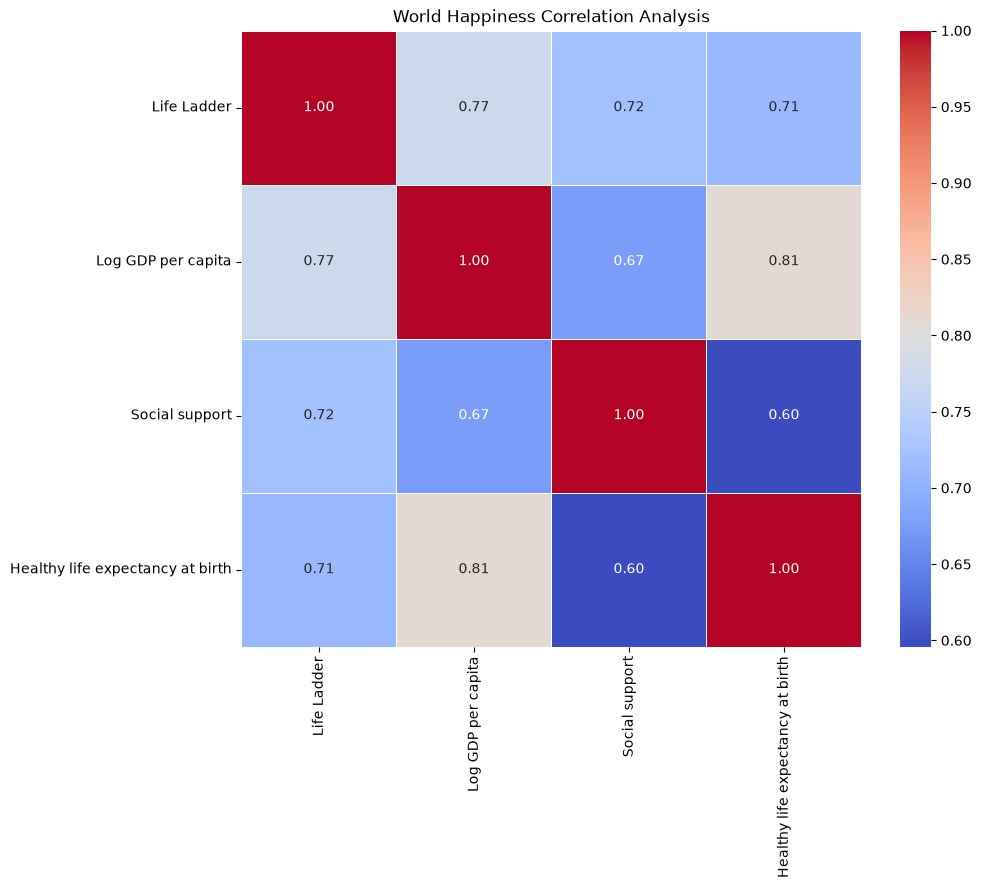

In [13]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('World Happiness Correlation Analysis')
plt.show()

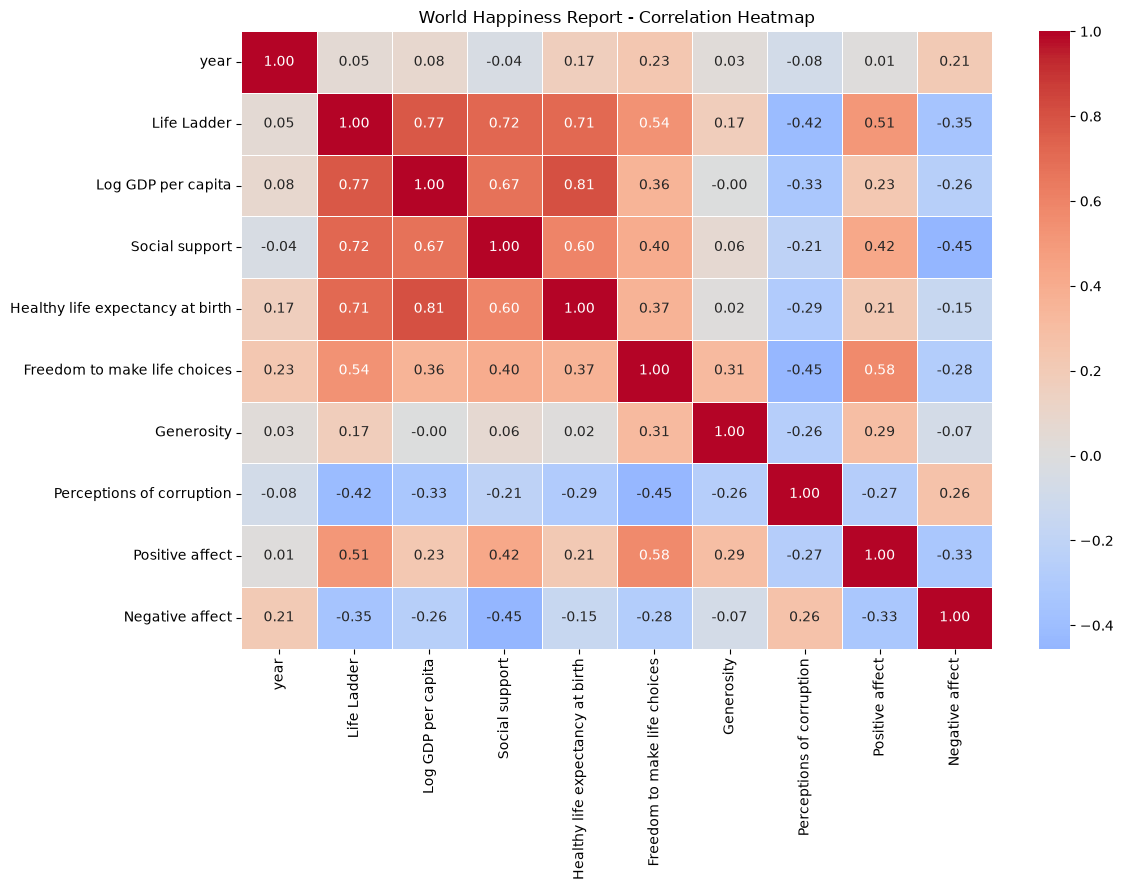

In [14]:
correlation_matrix = df.select_dtypes(include='number').corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5,center=0)
plt.title('World Happiness Report - Correlation Heatmap')
plt.tight_layout()
plt.show()

In [15]:
top_products = df.groupby('Country name')['Life Ladder'].sum().nlargest(10)
top_products

Country name
Denmark           137.952476
Sweden            132.574179
Canada            131.343368
Israel            130.299498
Costa Rica        127.718630
United States     126.524811
Netherlands       126.486673
United Kingdom    124.012659
New Zealand       123.431903
Australia         123.119217
Name: Life Ladder, dtype: float64

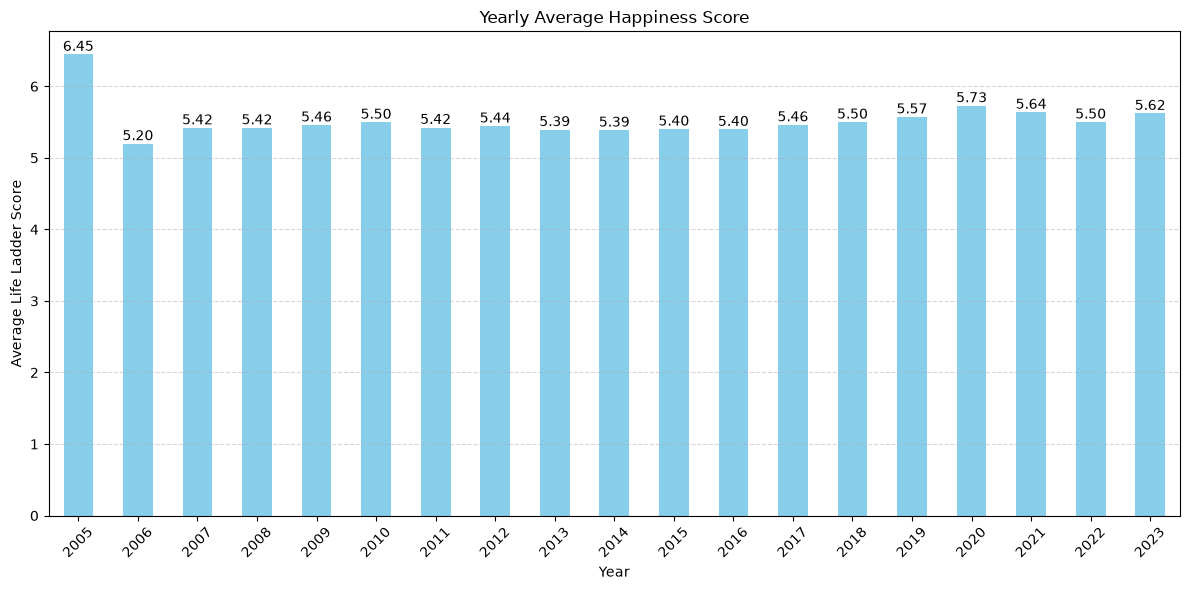

In [16]:
# Yearly Happiness Bar Chart

yearly_avg = df.groupby('year')['Life Ladder'].mean()

plt.figure(figsize=(12, 6))

yearly_avg.plot(kind='bar', color='skyblue')

plt.title('Yearly Average Happiness Score')
plt.xlabel('Year')
plt.ylabel('Average Life Ladder Score')

# Display Average Values on Bars
for i, value in enumerate(yearly_avg):
    plt.text(i, value + 0.05, f'{value:.2f}', ha='center')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [17]:
yearly_avg=df.groupby('year')['Life Ladder'].sum()
yearly_avg

year
2005    174.046435
2006    462.527241
2007    552.665723
2008    596.040936
2009    622.170974
2010    681.600987
2011    791.916825
2012    767.549273
2013    733.489004
2014    775.622410
2015    766.934680
2016    760.889700
2017    802.681957
2018    775.314362
2019    796.652251
2020    664.394536
2021    687.615526
2022    769.873261
2023    775.671911
Name: Life Ladder, dtype: float64

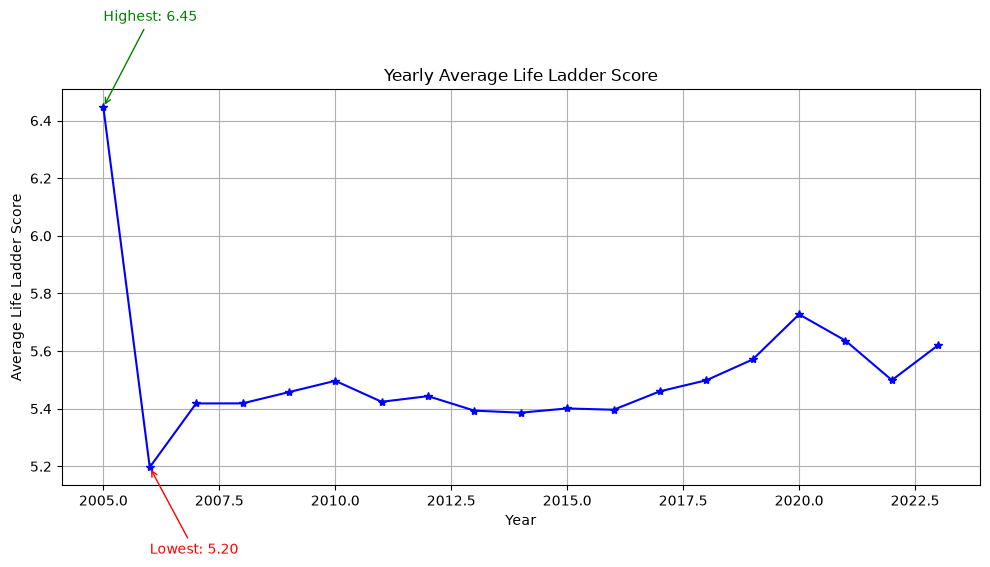

In [18]:
# Yearly Happiness Line Chart

yearly_avg = df.groupby('year')['Life Ladder'].mean()

plt.figure(figsize=(10, 6))

yearly_avg.plot(kind='line', marker='*', color='blue')

plt.title('Yearly Average Life Ladder Score')
plt.xlabel('Year')
plt.ylabel('Average Life Ladder Score')

# Find Highest and Lowest Happiness Years
max_year = yearly_avg.idxmax()
min_year = yearly_avg.idxmin()

# Annotate Highest Point
plt.annotate(
    f'Highest: {yearly_avg[max_year]:.2f}',
    xy=(max_year, yearly_avg[max_year]),
    xytext=(max_year, yearly_avg[max_year] + 0.3),
    arrowprops=dict(arrowstyle='->', color='green'),
    color='green'
)

# Annotate Lowest Point
plt.annotate(
    f'Lowest: {yearly_avg[min_year]:.2f}',
    xy=(min_year, yearly_avg[min_year]),
    xytext=(min_year, yearly_avg[min_year] - 0.3),
    arrowprops=dict(arrowstyle='->', color='red'),
    color='red'
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
yearly_happiness = df.groupby('year')['Life Ladder'].sum()
yearly_happiness

year
2005    174.046435
2006    462.527241
2007    552.665723
2008    596.040936
2009    622.170974
2010    681.600987
2011    791.916825
2012    767.549273
2013    733.489004
2014    775.622410
2015    766.934680
2016    760.889700
2017    802.681957
2018    775.314362
2019    796.652251
2020    664.394536
2021    687.615526
2022    769.873261
2023    775.671911
Name: Life Ladder, dtype: float64

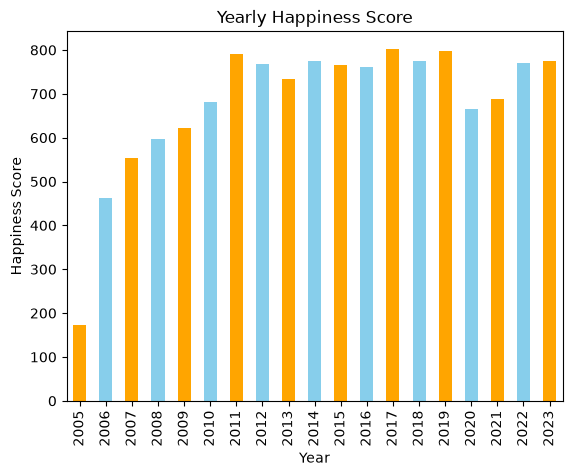

The year with the highest happiness score is 2017 with a score of 802.6819565296173.


In [20]:
# plot the bar chart for yearly happiness score
yearly_happiness.plot(kind='bar', color=['orange', 'skyblue'])
plt.title('Yearly Happiness Score')
plt.xlabel('Year')
plt.ylabel('Happiness Score')
plt.show()

# identify year with highest happiness score
happiness_year=yearly_happiness.idxmax()
happiness_value=yearly_happiness.max()
print(f"The year with the highest happiness score is {happiness_year} with a score of {happiness_value}.")



In [21]:
df

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.164055,0.881686,0.414297,0.258195
1,Afghanistan,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.187297,0.850035,0.481421,0.237092
2,Afghanistan,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.117861,0.706766,0.516907,0.275324
3,Afghanistan,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.160098,0.731109,0.479835,0.267175
4,Afghanistan,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.234157,0.775620,0.613513,0.267919
...,...,...,...,...,...,...,...,...,...,...,...
2358,Zimbabwe,2019,2.693523,7.697755,0.759162,53.099998,0.631908,-0.050874,0.830652,0.658434,0.235354
2359,Zimbabwe,2020,3.159802,7.596050,0.717243,53.575001,0.643303,0.002848,0.788523,0.660658,0.345736
2360,Zimbabwe,2021,3.154578,7.656878,0.685151,54.049999,0.667636,-0.079007,0.756945,0.609917,0.241682
2361,Zimbabwe,2022,3.296220,7.670073,0.666172,54.525002,0.651987,-0.072935,0.752632,0.640609,0.191350


In [22]:
# Analyze country-wise happiness behavior
country_data = df.groupby('Country name').agg({
    'Life Ladder': 'mean',
    'Healthy life expectancy at birth': 'mean',
    'Social support': 'mean'
})

country_data = country_data.rename(columns={
    'Life Ladder': 'Average Happiness',
    'Healthy life expectancy at birth': 'Average Healthy Life Expectancy',
    'Social support': 'Average Social Support'
})
country_data

,Average Happiness,Average Healthy Life Expectancy,Average Social Support
Country name,,,
Afghanistan,3.219917,52.711667,0.476654
Albania,5.072808,68.548750,0.714302
Algeria,5.391880,66.136363,0.813748
Angola,4.420299,52.150001,0.737973
Argentina,6.289722,66.700000,0.901894
...,...,...,...
Venezuela,5.950996,64.854445,0.902655
Vietnam,5.437579,64.900000,0.827821
Yemen,3.861960,58.081071,0.755336


In [23]:
# Manual Classification

def classify_happiness(row):
    if row['Average Happiness'] >= 7 and row['Average Social Support'] >= 0.75:
        return 'High Happiness'
    elif row['Average Happiness'] >= 5:
        return 'Medium Happiness'
    else:
        return 'Low Happiness'


# Apply the function to classify countries
country_data['Happiness Category'] = country_data.apply(classify_happiness, axis=1)

# Count the number of countries in each category
category_counts = country_data['Happiness Category'].value_counts()

category_counts

Happiness Category
Medium Happiness    83
Low Happiness       66
High Happiness      16
Name: count, dtype: int64

High Happiness group: 16 countries
Low Happiness group: 66 countries
Medium Happiness group: 83 countries


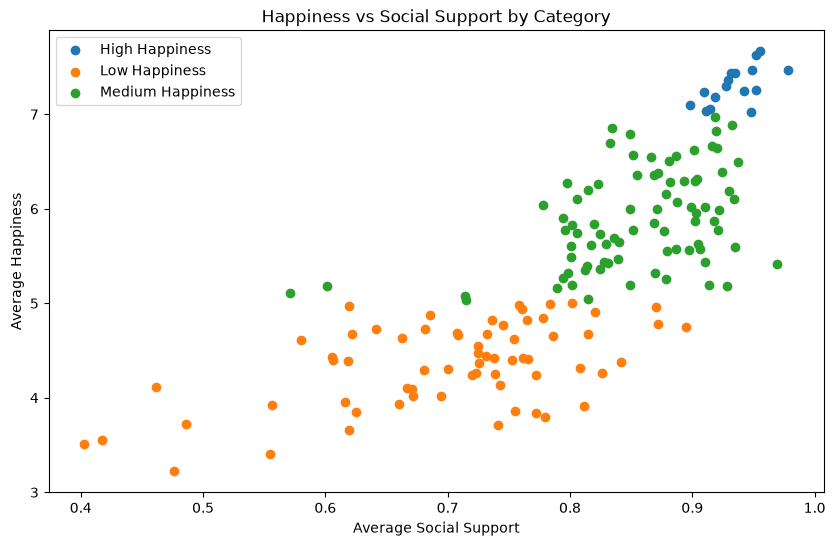

In [24]:
# Scatter Plot

plt.figure(figsize=(10, 6))

for label, group in country_data.groupby('Happiness Category'):
    print(f'{label} group: {len(group)} countries')
    plt.scatter(group['Average Social Support'], group['Average Happiness'], label=label)

plt.xlabel('Average Social Support')
plt.ylabel('Average Happiness')
plt.title('Happiness vs Social Support by Category')
plt.legend()
plt.show()

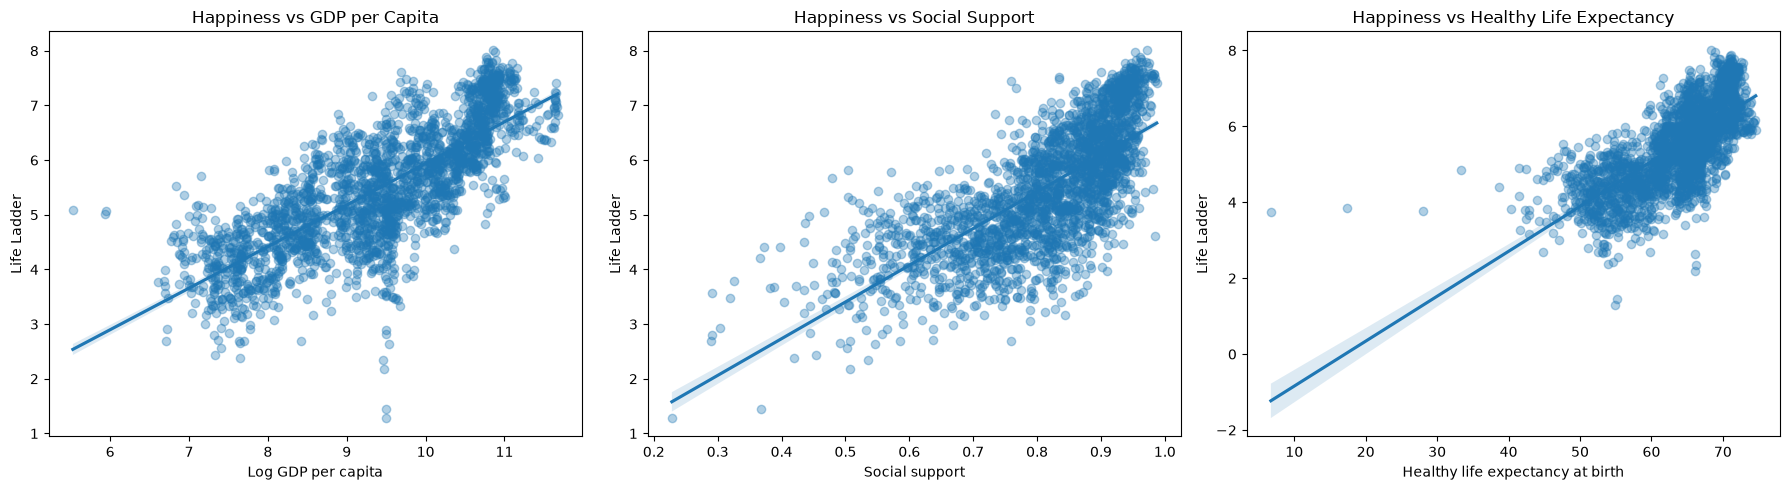

In [25]:
# Visualize Happiness vs GDP, Social Support and Healthy Life Expectancy

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.regplot(data=df,x='Log GDP per capita',y='Life Ladder',ax=axes[0],scatter_kws={'alpha': 0.35})
axes[0].set_title('Happiness vs GDP per Capita')
sns.regplot(data=df,x='Social support',y='Life Ladder',ax=axes[1],scatter_kws={'alpha': 0.35})
axes[1].set_title('Happiness vs Social Support')
sns.regplot(data=df,x='Healthy life expectancy at birth',y='Life Ladder',ax=axes[2],scatter_kws={'alpha': 0.35})
axes[2].set_title('Happiness vs Healthy Life Expectancy')
plt.tight_layout()
plt.show()

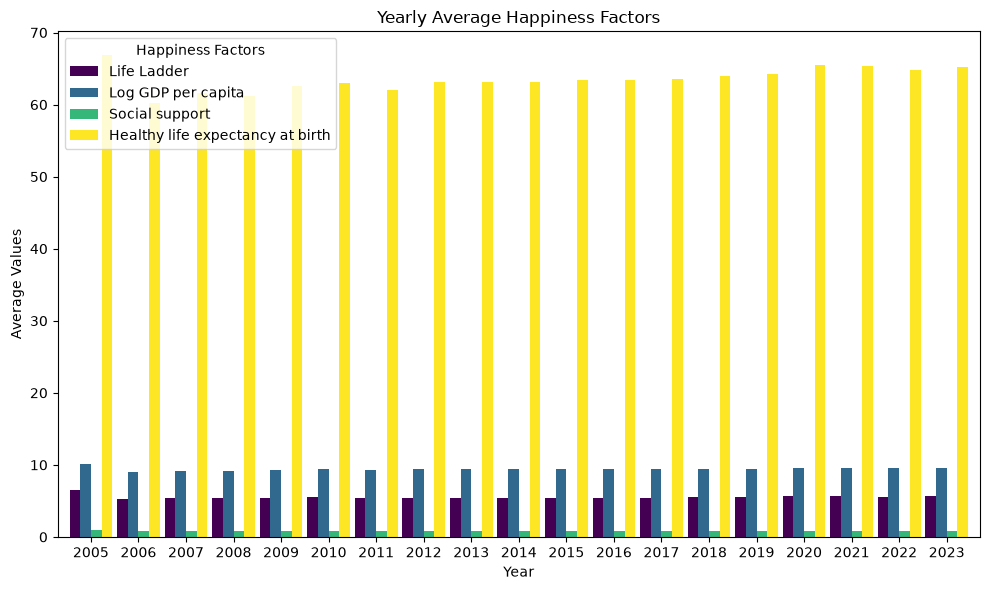

In [26]:
# Yearly Average of Happiness Factors
yearly = df.groupby('year')[['Life Ladder', 'Log GDP per capita',
                              'Social support', 'Healthy life expectancy at birth']].mean()
yearly.plot(kind='bar', figsize=(10, 6), width=0.9, colormap='viridis')
plt.title('Yearly Average Happiness Factors')
plt.xlabel('Year')
plt.ylabel('Average Values')
plt.xticks(rotation=0)
plt.legend(title='Happiness Factors')
plt.tight_layout()
plt.show()

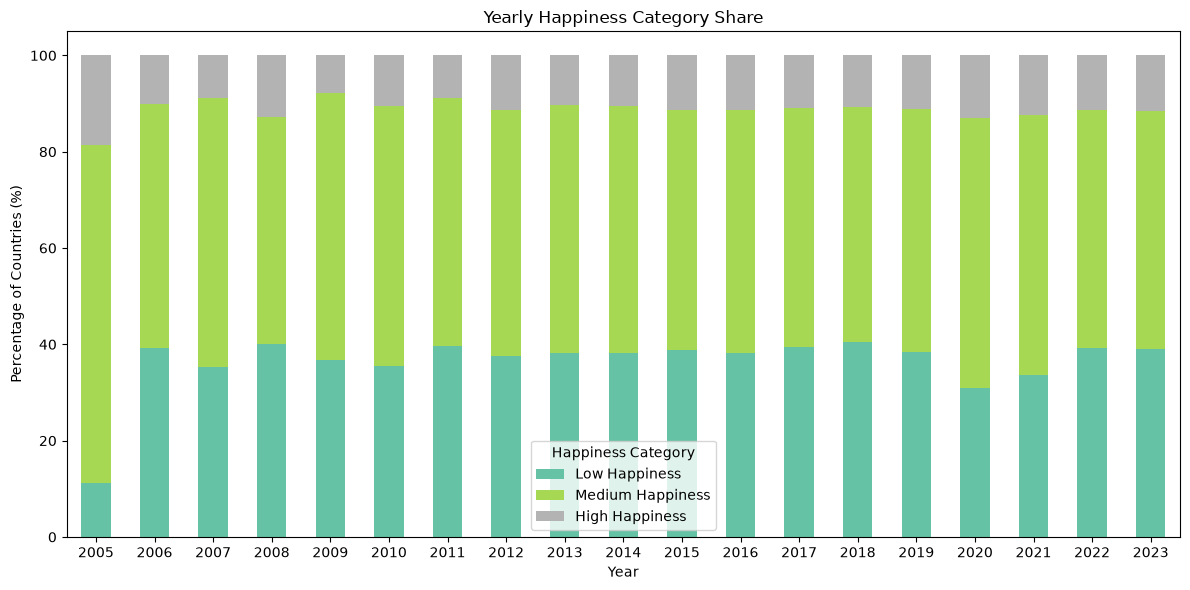

In [27]:
# Add Happiness Category
df['Happiness Category'] = df['Country name'].map(
    country_data['Happiness Category']
)

# Yearly Happiness Category (Stacked Bar)

category_share = pd.crosstab(
    df['year'],
    df['Happiness Category'],
    normalize='index'
) * 100

category_share = category_share.reindex(
    columns=['Low Happiness', 'Medium Happiness', 'High Happiness'],
    fill_value=0
)

category_share.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='Set2'
)

plt.title('Yearly Happiness Category Share')
plt.xlabel('Year')
plt.ylabel('Percentage of Countries (%)')
plt.xticks(rotation=0)
plt.legend(title='Happiness Category')
plt.tight_layout()
plt.show()

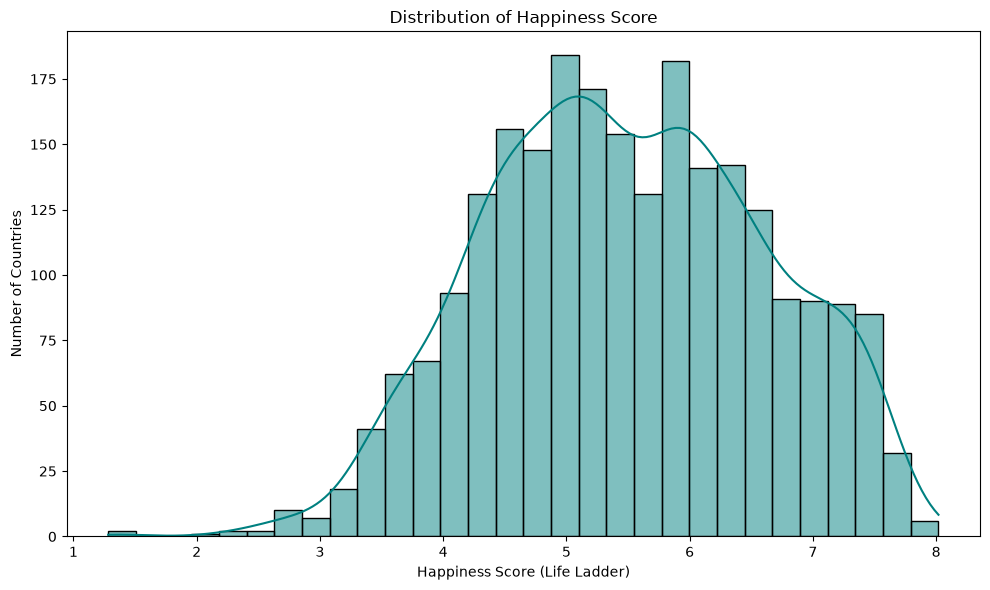

In [28]:
# Distribution of Happiness Score (Seaborn)

plt.figure(figsize=(10, 6))
sns.histplot(df['Life Ladder'], bins=30, kde=True, color='teal')
plt.title('Distribution of Happiness Score')
plt.xlabel('Happiness Score (Life Ladder)')
plt.ylabel('Number of Countries')
plt.tight_layout()
plt.show()

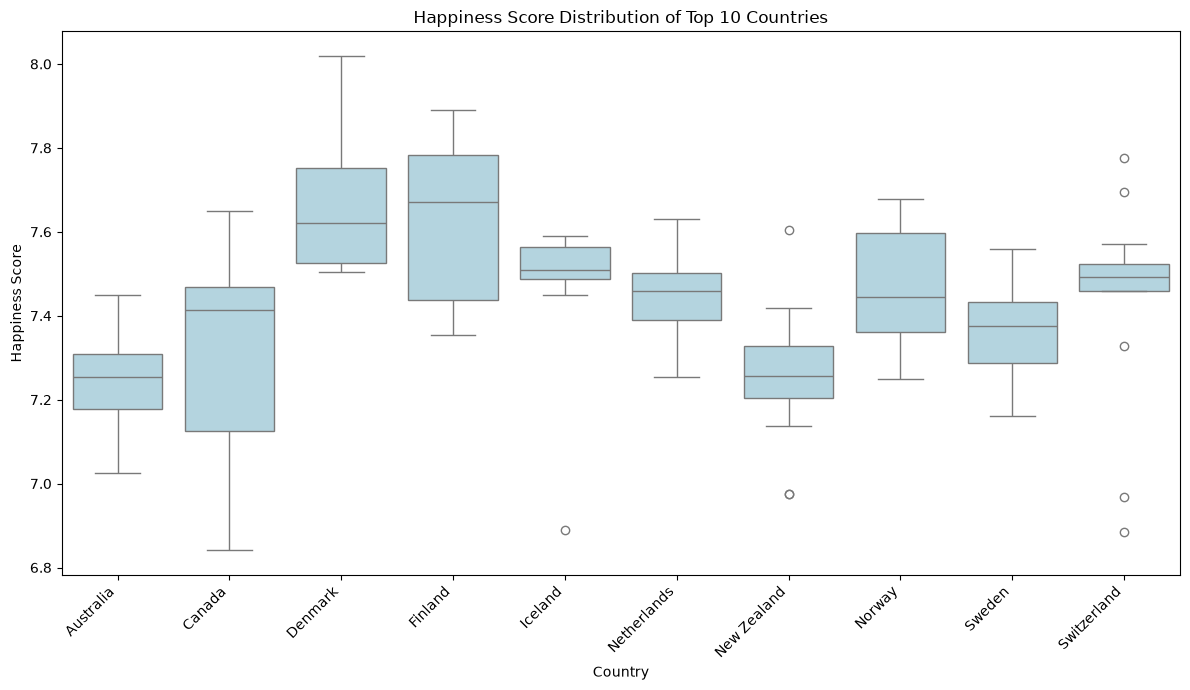

In [29]:
# Top 10 Countries by Average Happiness Score

top_countries = df.groupby('Country name')['Life Ladder'].mean().nlargest(10).index
filtered_df = df[df['Country name'].isin(top_countries)]
plt.figure(figsize=(12, 7))
sns.boxplot(data=filtered_df, x='Country name', y='Life Ladder', color='lightblue')
plt.title('Happiness Score Distribution of Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Happiness Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

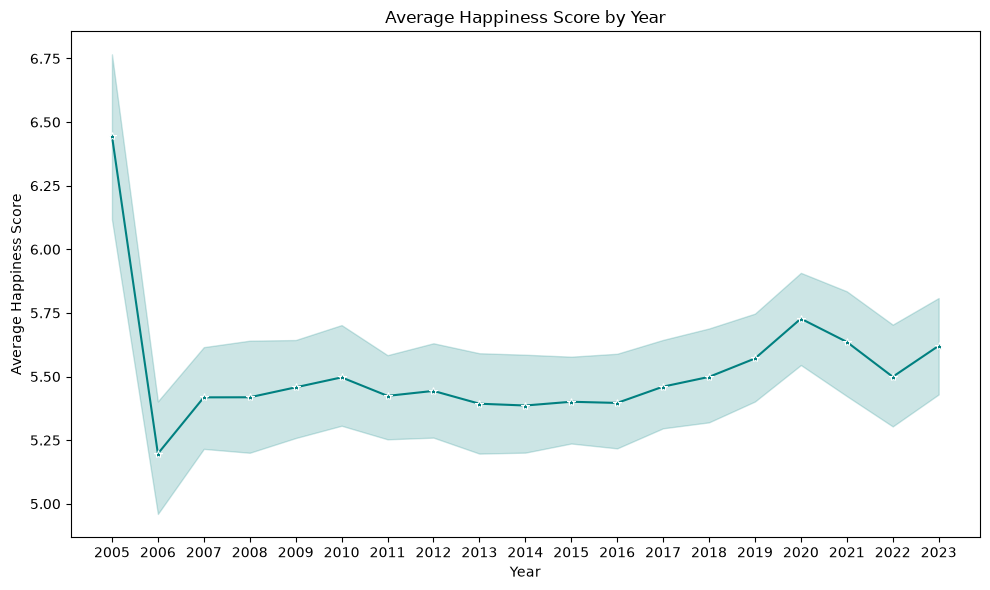

In [30]:
# Yearly pattern: Happiness Score (Seaborn)

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='year', y='Life Ladder',
             marker='*', color='teal')
plt.title('Average Happiness Score by Year')
plt.xlabel('Year')
plt.ylabel('Average Happiness Score')
plt.xticks(sorted(df['year'].unique()), rotation=0)
plt.tight_layout()
plt.show()

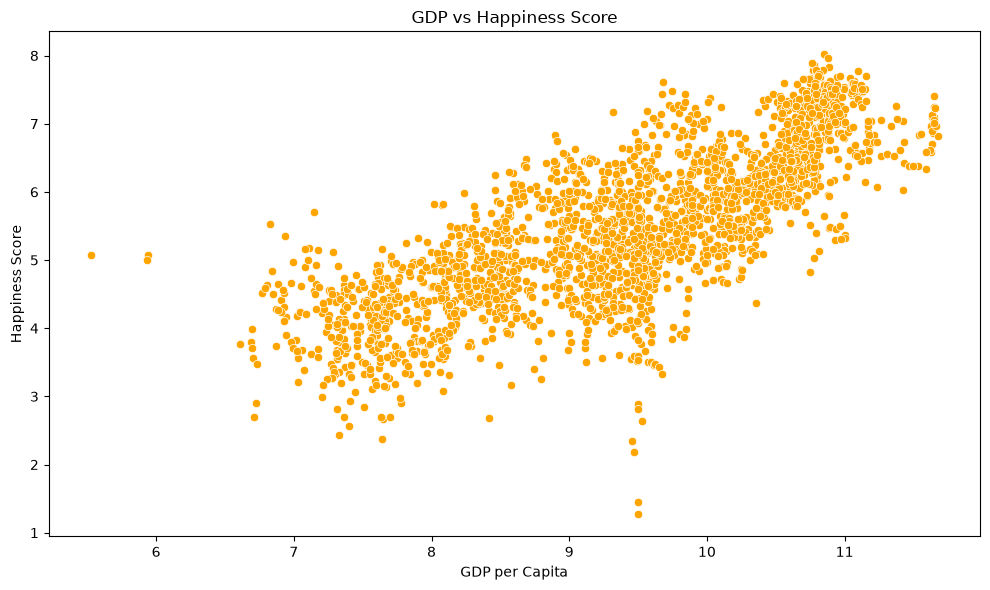

In [31]:
# GDP vs Happiness Score

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Log GDP per capita',y='Life Ladder',color='orange')
plt.title('GDP vs Happiness Score')
plt.xlabel('GDP per Capita')
plt.ylabel('Happiness Score')
plt.tight_layout()
plt.show()

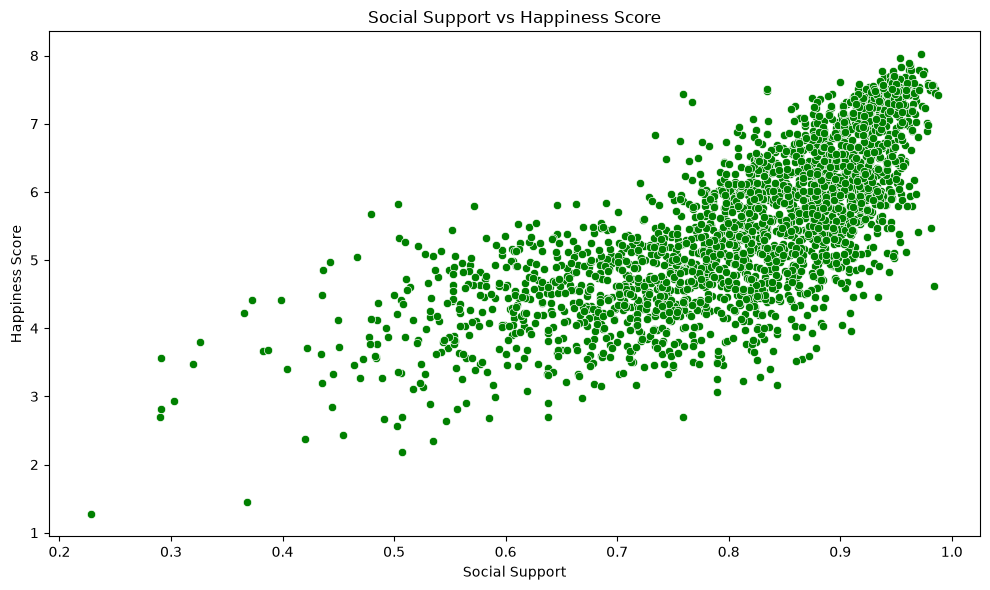

In [32]:
# Social Support vs Happiness Score

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Social support',y='Life Ladder',color='green')
plt.title('Social Support vs Happiness Score')
plt.xlabel('Social Support')
plt.ylabel('Happiness Score')
plt.tight_layout()
plt.show()

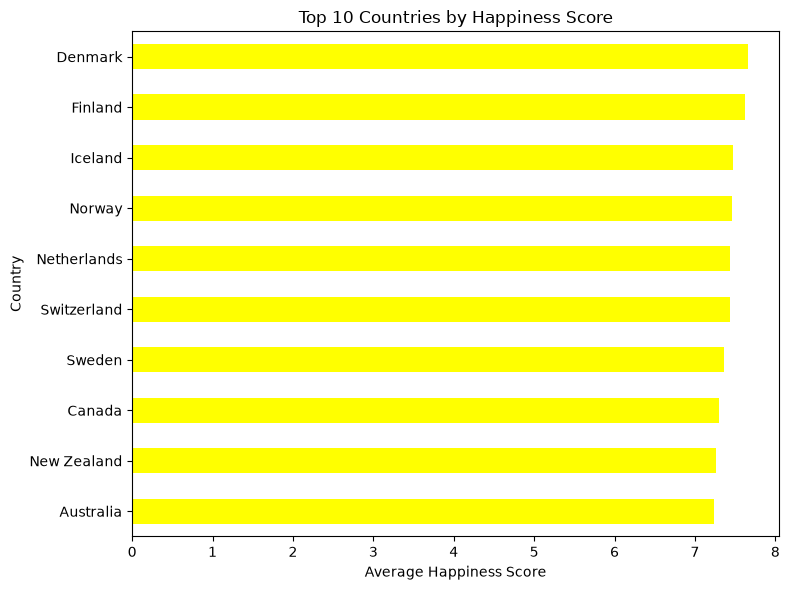

In [33]:
# Country vs Happiness Score

country_happiness = df.groupby('Country name')['Life Ladder'].mean().sort_values()
country_happiness.tail(10).plot(kind='barh',color='yellow',figsize=(8, 6))
plt.title('Top 10 Countries by Happiness Score')
plt.xlabel('Average Happiness Score')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

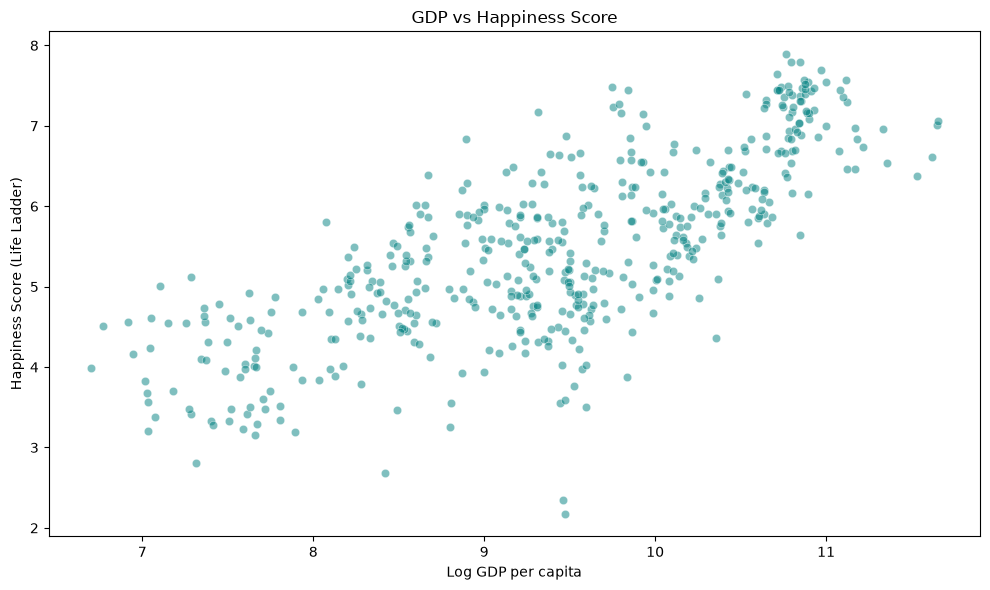

In [34]:
# GDP vs Happiness Score (Scatter Plot)

sample = df.sample(min(500, len(df)), random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample,x='Log GDP per capita',y='Life Ladder',alpha=0.5,color='teal')
plt.title('GDP vs Happiness Score')
plt.xlabel('Log GDP per capita')
plt.ylabel('Happiness Score (Life Ladder)')
plt.tight_layout()
plt.show()

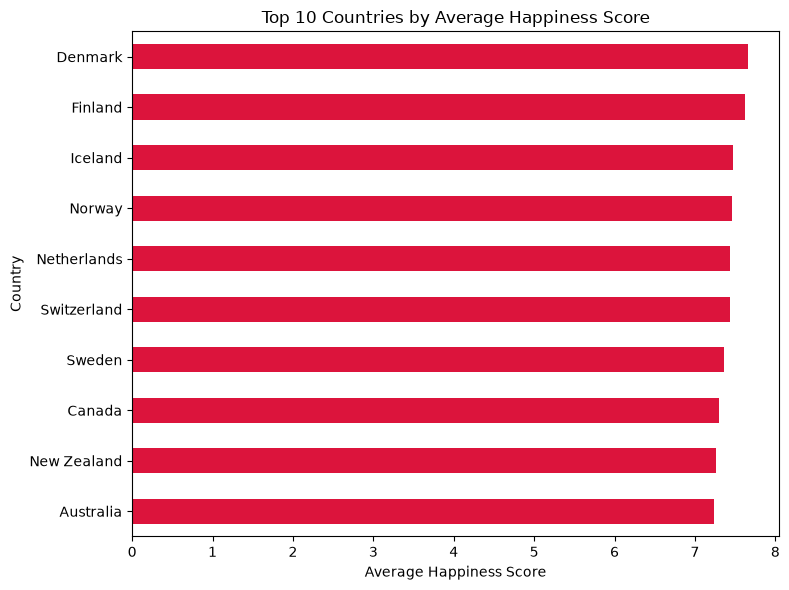

In [35]:
# Happiness Score by Country

happiness_pct = df.groupby('Country name')['Life Ladder'].mean()
happiness_pct.sort_values().tail(10).plot(kind='barh',color='crimson',figsize=(8, 6))
plt.title('Top 10 Countries by Average Happiness Score')
plt.xlabel('Average Happiness Score')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

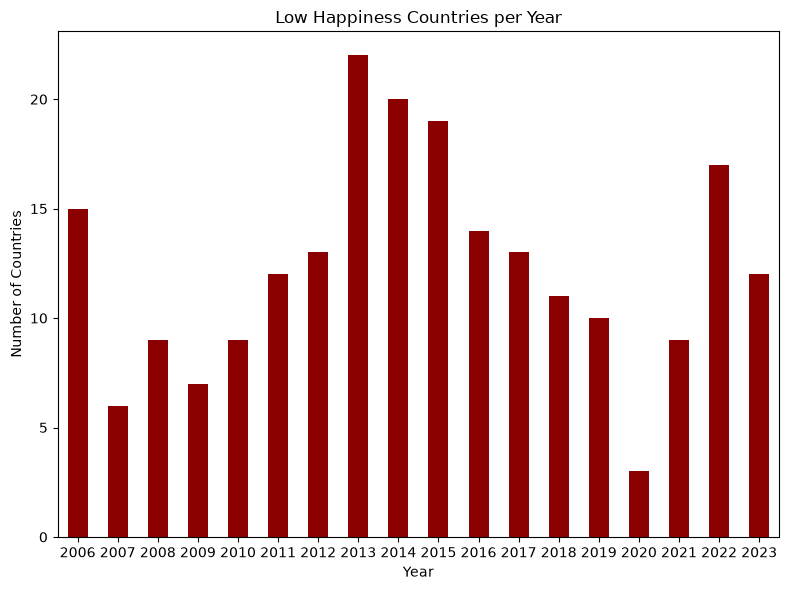

In [36]:
# Low Happiness Countries per Year

low_happiness = df[df['Life Ladder'] < 4].groupby('year').size()
low_happiness.plot(kind='bar',color='darkred',figsize=(8, 6))
plt.title('Low Happiness Countries per Year')
plt.xlabel('Year')
plt.ylabel('Number of Countries')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# 🌍 Global Happiness Data Analysis

sns.set_style('whitegrid')

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display available columns
print("Dataset Columns:", df.columns.tolist())

# Country-wise Data Aggregation
daily_happiness = (
    df.groupby('Country name').agg(
          Happiness_Score=('Life Ladder', 'mean'),
          GDP=('Log GDP per capita', 'mean'),
          Social_Support=('Social support', 'mean'),
          Life_Expectancy=('Healthy life expectancy at birth', 'mean'),
          Freedom=('Freedom to make life choices', 'mean'),
          Generosity=('Generosity', 'mean'),
          Corruption=('Perceptions of corruption', 'mean')
      )
      .reset_index()
)
print("\nTotal Countries:", daily_happiness.shape[0])
daily_happiness.head()

Dataset Columns: ['Country name', 'year', 'Life Ladder', 'Log GDP per capita', 'Social support', 'Healthy life expectancy at birth', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Positive affect', 'Negative affect', 'Happiness Category']

Total Countries: 165


,Country name,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Afghanistan,3.219917,7.841267,0.476654,52.711667,0.480475,0.045933,0.835824
1,Albania,5.072808,9.416875,0.714302,68.548750,0.694877,-0.068280,0.868671
2,Algeria,5.391880,9.338236,0.813748,66.136363,0.566241,-0.112374,0.708133
3,Angola,4.420299,8.985547,0.737973,52.150001,0.455957,-0.093218,0.867018
4,Argentina,6.289722,10.028808,0.901894,66.700000,0.777786,-0.153203,0.839019


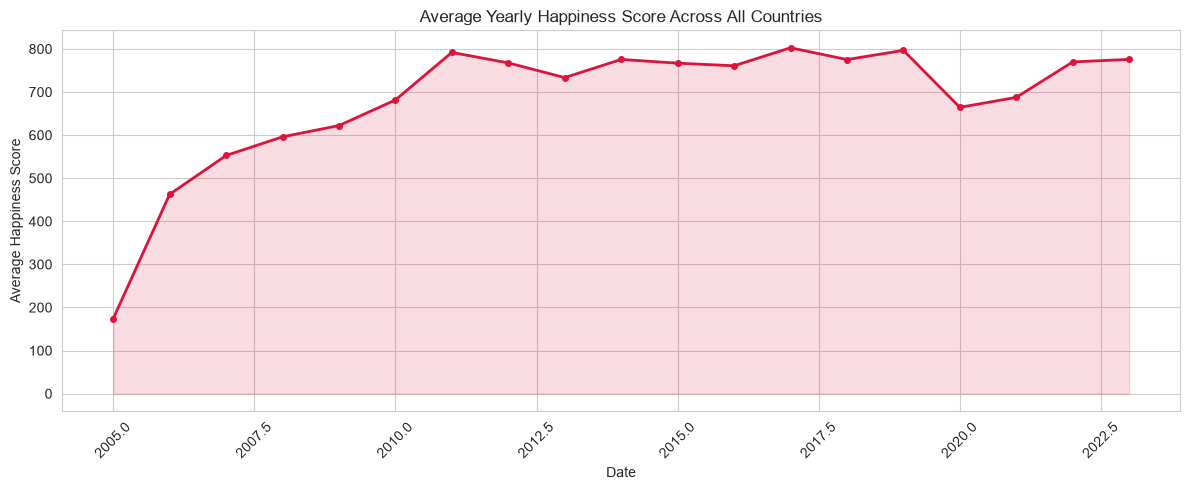

In [44]:
# 📊 Yearly Happiness Trend

df['YearMonth'] = pd.to_datetime(df['year'].astype(str) + '-01-01')
plt.figure(figsize=(12, 5))
plt.plot(yearly_happiness.index,yearly_happiness.values,color='crimson',linewidth=2,marker='o',markersize=4)
plt.fill_between(yearly_happiness.index,yearly_happiness.values,alpha=0.15,color='crimson')
plt.title('Average Yearly Happiness Score Across All Countries')
plt.xlabel('Date')
plt.ylabel('Average Happiness Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

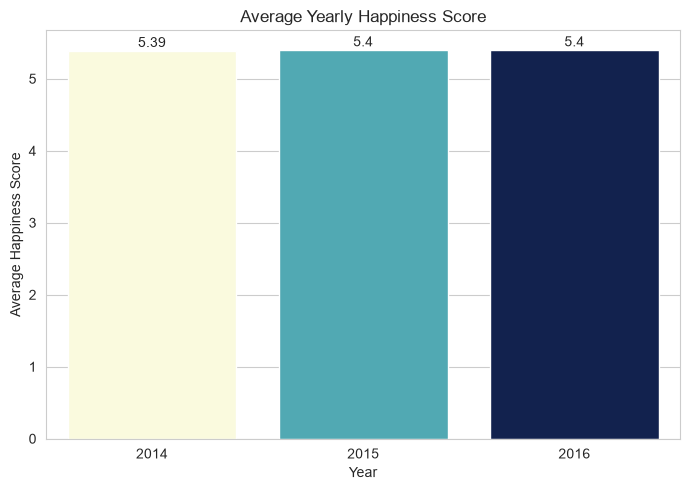

In [45]:
# 📊 Yearly Average Happiness Score

# Select complete yearly data
full = df[df['year'].between(2014, 2016)]

# Calculate yearly average happiness
yearly_happiness = full.groupby('year')['Life Ladder'].mean().round(2)

plt.figure(figsize=(7, 5))

ax = sns.barplot(x=yearly_happiness.index,y=yearly_happiness.values,hue=yearly_happiness.index,palette='YlGnBu',legend=False)

# Display values on bars
for i, v in enumerate(yearly_happiness.values):
    ax.text(i, v + 0.05, str(v), ha='center')
plt.title('Average Yearly Happiness Score')
plt.xlabel('Year')
plt.ylabel('Average Happiness Score')
plt.tight_layout()
plt.show()

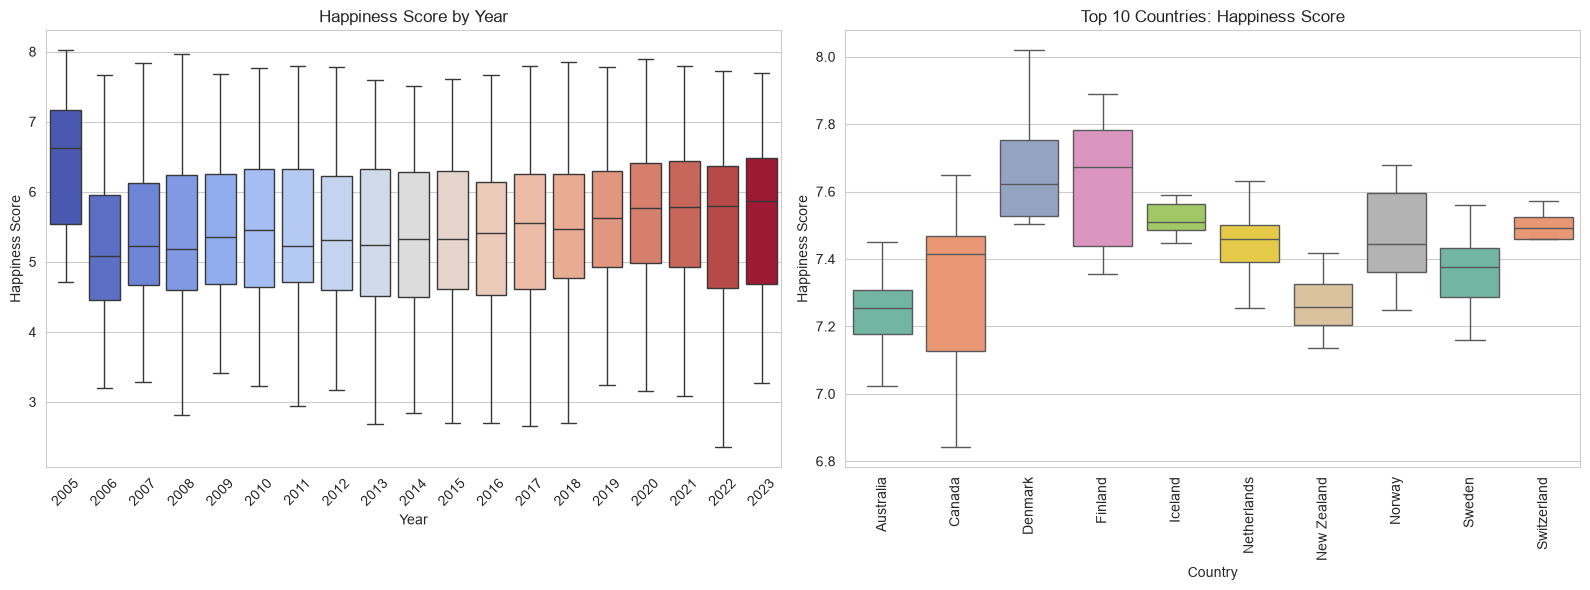


Average Happiness Score by Year:
year
2005    6.45
2006    5.20
2007    5.42
2008    5.42
2009    5.46
2010    5.50
2011    5.42
2012    5.44
2013    5.39
2014    5.39
2015    5.40
2016    5.40
2017    5.46
2018    5.50
2019    5.57
2020    5.73
2021    5.64
2022    5.50
2023    5.62
Name: Life Ladder, dtype: float64


In [50]:
# 📊 Happiness Score by Year and Top 10 Countries

# Calculate Top 10 Countries by Average Happiness Score
top10 = (df.groupby('Country name')['Life Ladder'].mean().nlargest(10).index)
top10_df = df[df['Country name'].isin(top10)]

# Create Subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot 1: Happiness Score by Year
sns.boxplot( data=df,x='year',y='Life Ladder',hue='year',palette='coolwarm',legend=False,showfliers=False,ax=axes[0])
axes[0].set_title('Happiness Score by Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Happiness Score')
axes[0].tick_params(axis='x', rotation=45)

# Boxplot 2: Top 10 Countries
sns.boxplot(data=top10_df,x='Country name',y='Life Ladder',hue='Country name',palette='Set2',legend=False,showfliers=False,ax=axes[1])
axes[1].set_title('Top 10 Countries: Happiness Score')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Happiness Score')
axes[1].tick_params(axis='x', rotation=90)

# Adjust Layout
plt.tight_layout()
plt.show()

# Average Happiness by Year
print("\nAverage Happiness Score by Year:")
print(df.groupby('year')['Life Ladder'].mean().round(2))

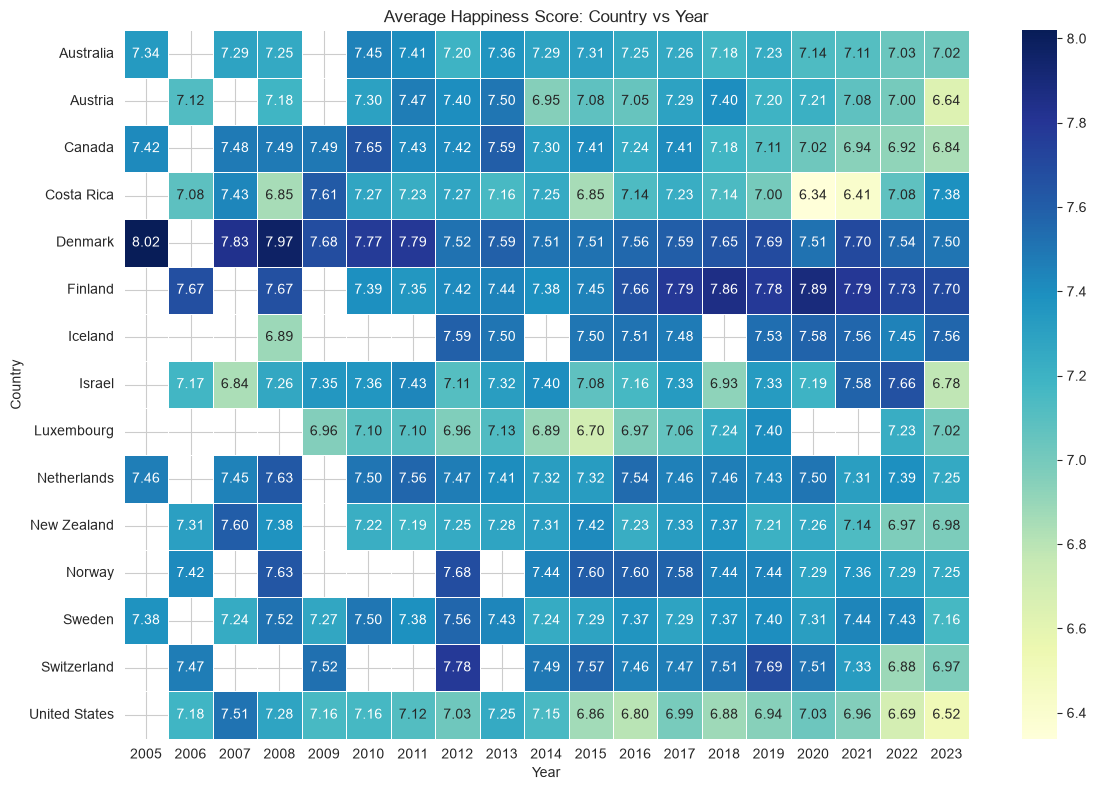

In [51]:
# 🌍 Country vs Year Happiness Heatmap

# Calculate Top 15 Countries by Average Happiness
top_countries = (df.groupby('Country name')['Life Ladder'].mean().nlargest(15).index)

# Filter Top Countries
top_df = df[df['Country name'].isin(top_countries)]

# Create Pivot Table
heat = top_df.pivot_table(index='Country name',columns='year',values='Life Ladder',aggfunc='mean')

# Plot Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(heat,annot=True,fmt='.2f',cmap='YlGnBu',linewidths=0.5)
plt.title('Average Happiness Score: Country vs Year')
plt.xlabel('Year')
plt.ylabel('Country')
plt.tight_layout()
plt.show()